### Prof. Alfio Ferrara

# Il contesto

##  Metodologie informatiche nelle discipline umanistiche
##### A.A. 2026/2027

---

Nel notebook precedente abbiamo visto che ogni parola può avere un vettore appreso. Ma quei vettori dipendevano dal compito: li avevamo ottenuti per prevedere il **clima** di una città, con cinque etichette decise da una persona. Le posizioni riflettevano solo quelle cinque classi.

Ora cambiamo il compito, e non servono più etichette. Il testo stesso ci dà il problema da risolvere: **indovinare una parola guardando le parole che le stanno intorno**. Il significato generale di una parola, ci aspettiamo, è nel modo in cui viene usata.

## Il contesto di una parola

Il **contesto** di una parola è l'insieme delle parole vicine, nella stessa frase. Fissiamo una finestra di due parole prima e due dopo. Ogni posizione di ogni frase diventa un esempio: le parole intorno sono l'ingresso, la parola in mezzo è quella da indovinare.

Usiamo gli stessi cento testi sulle città, divisi in frasi.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with open('data/clima_citta.json') as f:
    dataset = json.load(f)

classi_clima = ['tropicale', 'desertico', 'mediterraneo', 'temperato', 'polare']

frasi, doc_della_frase = [], []
for i, voce in enumerate(dataset):
    for frase in re.split(r'[.!?;]', voce['testo']):
        parole_frase = re.findall(r'[^\W\d_]+', frase.lower())
        if len(parole_frase) >= 3:
            frasi.append(parole_frase)
            doc_della_frase.append(i)

vocabolario = sorted({p for frase in frasi for p in frase})
posizione = {p: j for j, p in enumerate(vocabolario)}
V = len(vocabolario)

FINESTRA = 2
esempi = []
for frase, i in zip(frasi, doc_della_frase):
    for k, parola in enumerate(frase):
        contesto = [frase[j] for j in range(max(0, k - FINESTRA), min(len(frase), k + FINESTRA + 1)) if j != k]
        esempi.append((contesto, posizione[parola], i))

print(len(frasi), 'frasi,', sum(len(f) for f in frasi), 'parole,', V, 'parole diverse')
print('esempi (contesto → parola):', len(esempi))
print('\nfrase:', ' '.join(frasi[0]), '\n')
print(pd.DataFrame({'contesto': [' '.join(c) for c, _, _ in esempi[:8]],
                    'parola da indovinare': [vocabolario[t] for _, t, _ in esempi[:8]]}).to_string())

200 frasi, 2943 parole, 614 parole diverse
esempi (contesto → parola): 2943

frase: a singapore fa caldo e umido tutto l anno con temperature che variano di poco tra una stagione e l altra 

               contesto parola da indovinare
0          singapore fa                    a
1            a fa caldo            singapore
2   a singapore caldo e                   fa
3  singapore fa e umido                caldo
4  fa caldo umido tutto                    e
5       caldo e tutto l                umido
6        e umido l anno                tutto
7  umido tutto anno con                    l


## Un momento di riflessione

- Quante parole di contesto ha ogni esempio? Perché le prime e le ultime parole di una frase ne hanno meno?
- Per ogni parola della frase abbiamo un esempio. Quanti esempi ha una parola molto frequente come *e*? E una rara come il nome di una città?
- Chi ha deciso la «risposta giusta» di ogni esempio? Serve una persona per etichettarli?
- Se due parole compaiono con gli stessi vicini, che cosa possiamo dire del modo in cui sono usate?
- La finestra è di due parole. Che cosa cambierebbe con una finestra di una sola parola o di una frase intera?

## Predire una parola dal contesto

La rete è la stessa di prima, con tre differenze.

1. **L'ingresso è il contesto**: un vettore con una componente per ogni parola del vocabolario, uguale alla frazione delle parole di contesto che sono quella parola. Le parole di contesto contano allo stesso modo, qualunque posizione abbiano.
2. **Il livello intermedio ha 16 dimensioni**, invece di 2, e non ha funzione di attivazione: è la **media delle righe di $W_1$** delle parole di contesto, cioè dei loro vettori.
3. **L'uscita ha una classe per ogni parola** del vocabolario: la rete assegna una probabilità a ogni parola possibile, con la softmax.

$$h = xW_1 \qquad p = \text{softmax}(hW_2 + b_2)$$

Il compito è sempre quello di far salire la probabilità della parola giusta, con lo stesso errore $-\ln p$ e la stessa discesa del gradiente. Prima del training i parametri sono casuali.

In [3]:
X = np.zeros((len(esempi), V))
for n, (contesto, _, _) in enumerate(esempi):
    for p in contesto:
        X[n, posizione[p]] += 1 / len(contesto)
y = np.array([t for _, t, _ in esempi])

def softmax(s):
    e = np.exp(s - s.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)

def inizializza(n_nascosti=16, seed=0):
    rng = np.random.default_rng(seed)
    return {'W1': rng.normal(scale=0.1, size=(V, n_nascosti)), 'W2': rng.normal(scale=0.1, size=(n_nascosti, V)), 'b2': np.zeros(V)}

def probabilita(par, X):
    return softmax(X @ par['W1'] @ par['W2'] + par['b2'])

def vettore_contesto(contesto):
    x = np.zeros(V)
    for p in contesto:
        x[posizione[p]] += 1 / len(contesto)
    return x

def prevedi(par, contesti, k=3):
    p = probabilita(par, np.array([vettore_contesto(c) for c in contesti]))
    righe = []
    for c, riga in zip(contesti, p):
        migliori = np.argsort(-riga)[:k]
        righe.append([' '.join(c)] + [f'{vocabolario[j]} ({riga[j]:.2f})' for j in migliori])
    return pd.DataFrame(righe, columns=['contesto'] + [f'{i + 1}ª' for i in range(k)])

contesti_prova = [
    ['fa', 'caldo', 'umido', 'tutto'],
    ['clima', 'e', 'umido', 'tutto'],
    ['estati', 'e', 'inverni', 'sono'],
    ['inverni', 'molto', 'lunghi', 'e'],
    ['il', 'clima', 'è', 'secco'],
]

par = inizializza()
print('W1:', par['W1'].shape, '| W2:', par['W2'].shape, '| parametri:', sum(v.size for v in par.values()))
print('probabilità se tutte le parole fossero equiprobabili:', round(1 / V, 4))
print()
print(prevedi(par, contesti_prova).to_string(index=False))

W1: (614, 16) | W2: (16, 614) | parametri: 20262
probabilità se tutte le parole fossero equiprobabili: 0.0016

              contesto                        1ª                2ª                 3ª
  fa caldo umido tutto           santiago (0.00) soleggiata (0.00)   frequenza (0.00)
   clima e umido tutto                 su (0.00)  invernali (0.00)  riflettono (0.00)
 estati e inverni sono            periodi (0.00)       nell (0.00)        nord (0.00)
inverni molto lunghi e            marcate (0.00)  ilulissat (0.00) vegetazione (0.00)
      il clima è secco insopportabilmente (0.00)  temporali (0.00)     marcate (0.00)


## Un momento di riflessione

- Quanti parametri ha la rete, rispetto a quella del notebook precedente? Da dove viene la differenza?
- Le previsioni prima del training sono ragionevoli? Quale probabilità ha ciascuna parola, rispetto a quella di una scelta a caso?
- Il livello intermedio è la media dei vettori delle parole di contesto. Che cosa succede se due contesti hanno le stesse parole in ordine diverso?
- Perché l'uscita ha una classe per ogni parola e non cinque come prima? Che cosa abbiamo tolto dal compito?

## Il training

Alleniamo con la discesa del gradiente su tutti gli esempi, 300 passi con $\eta = 20$. Senza funzione di attivazione le formule del gradiente sono quelle di prima, più semplici: non c'è la derivata della $\tanh$.

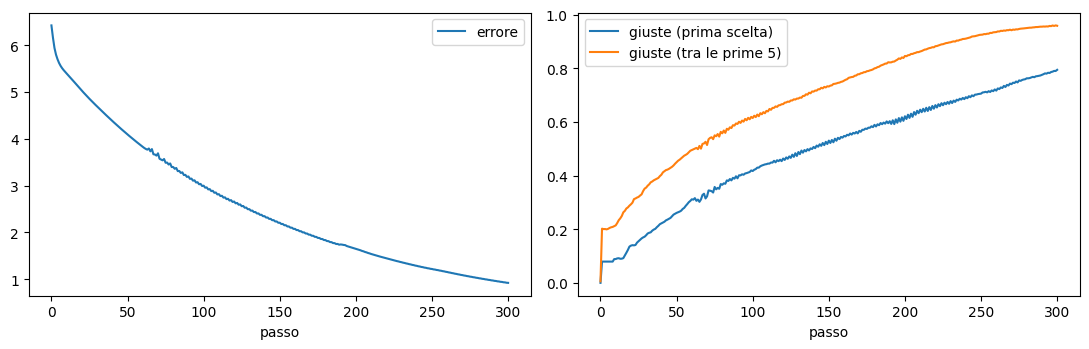

     errore  giuste (prima scelta)  giuste (tra le prime 5)
0     6.421                  0.001                    0.006
100   2.999                  0.417                    0.615
200   1.651                  0.621                    0.846
300   0.925                  0.794                    0.958


In [4]:
def addestra(par, X, y, eta=20.0, passi=300):
    par = {k: v.copy() for k, v in par.items()}
    Y = np.zeros((len(y), V))
    Y[np.arange(len(y)), y] = 1
    storia = []
    for _ in range(passi + 1):
        h = X @ par['W1']
        p = softmax(h @ par['W2'] + par['b2'])
        storia.append({'errore': -np.log(p[np.arange(len(y)), y]).mean(),
                       'giuste (prima scelta)': (p.argmax(axis=1) == y).mean(),
                       'giuste (tra le prime 5)': (np.argsort(-p, axis=1)[:, :5] == y[:, None]).any(axis=1).mean()})
        ds = (p - Y) / len(y)
        dh = ds @ par['W2'].T
        par['W2'] -= eta * h.T @ ds
        par['b2'] -= eta * ds.sum(axis=0)
        par['W1'] -= eta * X.T @ dh
    return par, pd.DataFrame(storia)

par_finale, storia = addestra(par, X, y)

fig, assi = plt.subplots(1, 2, figsize=(11, 3.6))
storia[['errore']].plot(ax=assi[0])
storia[['giuste (prima scelta)', 'giuste (tra le prime 5)']].plot(ax=assi[1])
for ax in assi:
    ax.set_xlabel('passo')
plt.tight_layout()
plt.show()

print(storia.iloc[[0, 100, 200, 300]].round(3).to_string())

## Un momento di riflessione

- Dopo 300 passi, quante volte la rete indovina la parola con la prima scelta? E tra le prime cinque?
- Indovinare la parola esatta è sempre possibile? Quando il contesto lascia più parole plausibili, ha senso pretendere di arrivare al 100%?
- L'errore è calcolato sugli stessi esempi usati per imparare. Quanto possiamo fidarci dei numeri? Che cosa potrebbe aver fatto la rete, con 20 mila parametri e meno di 3 mila esempi?
- Rispetto alle etichette dei climi, che cosa è cambiato nella quantità di «risposte giuste» a disposizione per imparare?

## Dopo il training: contesti nuovi

Rifacciamo le previsioni sugli stessi contesti di prima. Il primo è una frase vera del corpus, gli altri sono inventati: la rete non li ha mai visti uguali.

In [5]:
print(prevedi(par_finale, contesti_prova).to_string(index=False))

              contesto              1ª             2ª             3ª
  fa caldo umido tutto        e (0.82)   caldo (0.08)    dove (0.03)
   clima e umido tutto    caldo (0.97)   calde (0.01)   calda (0.01)
 estati e inverni sono moderate (0.49) tiepide (0.37) fresche (0.08)
inverni molto lunghi e   freddi (0.54)  mentre (0.10)    gelo (0.10)
      il clima è secco    caldo (0.93)       e (0.05)   avana (0.00)


## Un momento di riflessione

- Per il primo contesto, che è nel corpus, la rete è sicura? Che cosa potrebbe aver fatto, in questo caso, più che «capire»?
- Per i contesti inventati le previsioni sono sensate? Che tipo di parola mette al primo posto?
- Che cosa hanno in comune le parole tra le prime tre scelte di uno stesso contesto? Sono interscambiabili in quella frase?
- In «il clima è secco» la rete risponde *caldo*. È una risposta ragionevole? Che cosa ci dice sui dati con cui ha imparato?
- Per indovinare *caldo* o *freddi* la rete ha dovuto imparare qualcosa su di loro. Dove sta quello che ha imparato?

## I vettori delle parole

Quello che la rete ha imparato sta nelle righe di $W_1$: ogni parola ha ora un vettore di 16 numeri. Il vettore di una parola è appreso solo per fare bene il compito di indovinare parole dal contesto, ma può servire a molto altro. Per confrontare due vettori usiamo la **similarità del coseno**, come per i documenti. Guardiamo le parole più vicine a quelle scelte. Per confronto calcoliamo gli stessi vicini con un'altra rete: quella del notebook precedente, con 16 nodi nascosti e addestrata a classificare i climi (il **vettore per classe**).

In [6]:
conteggi = np.zeros((len(dataset), V))
for frase, i in zip(frasi, doc_della_frase):
    for p in frase:
        conteggi[i, posizione[p]] += 1
idf = np.log(len(dataset) / (conteggi > 0).sum(axis=0))
tfidf_doc = conteggi / conteggi.sum(axis=1, keepdims=True) * idf
tfidf_doc /= np.maximum(np.linalg.norm(tfidf_doc, axis=1, keepdims=True), 1e-12)
y_classi = np.array([classi_clima.index(v['clima']) for v in dataset])

def addestra_classi(n_nascosti=16, eta=2.0, passi=300, seed=0):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(scale=0.1, size=(V, n_nascosti)); b1 = np.zeros(n_nascosti)
    W2 = rng.normal(scale=0.1, size=(n_nascosti, 5)); b2 = np.zeros(5)
    Y = np.eye(5)[y_classi]
    for _ in range(passi + 1):
        h = np.tanh(tfidf_doc @ W1 + b1)
        p = softmax(h @ W2 + b2)
        ds = (p - Y) / len(Y)
        dz = (ds @ W2.T) * (1 - h ** 2)
        W1 -= eta * tfidf_doc.T @ dz; b1 -= eta * dz.sum(axis=0)
        W2 -= eta * h.T @ ds; b2 -= eta * ds.sum(axis=0)
    return W1, (p.argmax(axis=1) == y_classi).mean()

vettori_classe, accuratezza_classi = addestra_classi()
vettori_contesto = par_finale['W1']
print(f'rete per classe: accuratezza sui cento documenti {accuratezza_classi:.2f}\n')

def normalizza(E):
    return E / np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1e-9)

def vicine(E, parola, k=5):
    sim = normalizza(E) @ normalizza(E)[posizione[parola]]
    return [vocabolario[j] for j in np.argsort(-sim)[1:k + 1]]

scelte = ['umido', 'giugno', 'freddi', 'caldo', 'inverni', 'singapore']
print(pd.DataFrame({
    'parola': scelte,
    'vicine, vettore per classe': [', '.join(vicine(vettori_classe, p)) for p in scelte],
    'vicine, vettore da contesto': [', '.join(vicine(vettori_contesto, p)) for p in scelte],
}).to_string(index=False))

rete per classe: accuratezza sui cento documenti 1.00

   parola                        vicine, vettore per classe                    vicine, vettore da contesto
    umido          delle, primavera, umidità, intensi, alla       afoso, secco, soleggiata, vite, asciutte
   giugno  addolcite, umidità, dagli, pomeridiani, coincide permafrost, maggio, luglio, tifoni, escursione
   freddi    latitudine, regolari, paese, tiepide, distinte        tundra, gelidi, rigidi, lunghissimi, la
    caldo elevata, acquazzoni, temporali, allagano, umidità                tramonta, sul, d, terreno, sole
  inverni                mare, ha, dal, persistente, estati  svalbard, zurigo, acquazzoni, parigi, abidjan
singapore              regola, ushuaia, tregua, manila, qui    praga, reykjavik, scirocco, cade, fairbanks


## Un momento di riflessione

- Con il vettore per classe, le parole vicine che cosa hanno in comune con quella scelta? E con quello da contesto?
- Per *giugno* e *umido*, quali vicine vi sembrano più sensate? *giugno* è vicina a *maggio* e *luglio*: la rete sa che sono mesi? Che cosa ha osservato, davvero?
- Il vettore per classe poteva sapere che *maggio* e *giugno* sono mesi? Le cinque etichette contenevano questa informazione?
- Alcune vicine sono sbagliate o poco significative (le parole poco frequenti sono rumorose). Che cosa servirebbe per avere vettori più affidabili?
- Tra le vicine di *caldo* ci sono parole che avremmo voluto vedere? Quali mancano? Perché?

## Misurare la somiglianza grammaticale

Per avere un numero, e non solo qualche esempio, contiamo quante delle cinque parole più vicine hanno la stessa **categoria grammaticale** (nome, aggettivo, verbo, preposizione, ...) della parola di partenza. Le categorie le assegna spaCy, che la rete non ha mai visto. Consideriamo le parole che compaiono almeno quattro volte. Come riferimento, vettori casuali.

In [7]:
import spacy
nlp = spacy.load('it_core_news_lg')

categoria = {}
for frase in frasi:
    for t in nlp(' '.join(frase)):
        categoria.setdefault(t.text, t.pos_)
categorie = np.array([categoria.get(p, 'X') for p in vocabolario])
frequenza = np.bincount(y, minlength=V)
frequenti = np.flatnonzero(frequenza >= 4)

def quota_stessa_categoria(E, k=5):
    En = normalizza(E)[frequenti]
    sim = En @ En.T
    np.fill_diagonal(sim, -9)
    vicini = np.argsort(-sim, axis=1)[:, :k]
    return np.mean(categorie[frequenti][vicini] == categorie[frequenti][:, None])

casuali = np.random.default_rng(0).normal(size=(V, 16))
print(pd.Series({'vettori casuali': quota_stessa_categoria(casuali),
                 'vettore per classe': quota_stessa_categoria(vettori_classe),
                 'vettore da contesto': quota_stessa_categoria(vettori_contesto)}).round(2).to_string())
print('\nparole considerate:', len(frequenti))
print(pd.Series(categorie[frequenti]).value_counts().to_string())

vettori casuali        0.17
vettore per classe     0.24
vettore da contesto    0.35

parole considerate: 148
NOUN     44
ADJ      39
ADP      18
VERB     16
DET      12
ADV       9
NUM       3
PRON      2
CCONJ     2
AUX       2
SCONJ     1


## Un momento di riflessione

- Le tre quote sono molto diverse? Qual è la più alta, e di quanto supera il caso?
- Nessuno ha detto alla rete che *umido* è un aggettivo e *giugno* è un nome. Come ha ottenuto una somiglianza grammaticale?
- Perché il vettore per classe è più vicino al caso? A quale informazione dei testi non poteva accedere?
- La quota non arriva vicino a 1. Che cosa limita il risultato: pochi dati, poche dimensioni, un compito troppo semplice?

## Le parole nel piano

Proiettiamo i vettori da contesto a 16 dimensioni in due, con la direzione di massima variazione (PCA), come per i documenti. Le parole sono colorate secondo la categoria grammaticale.

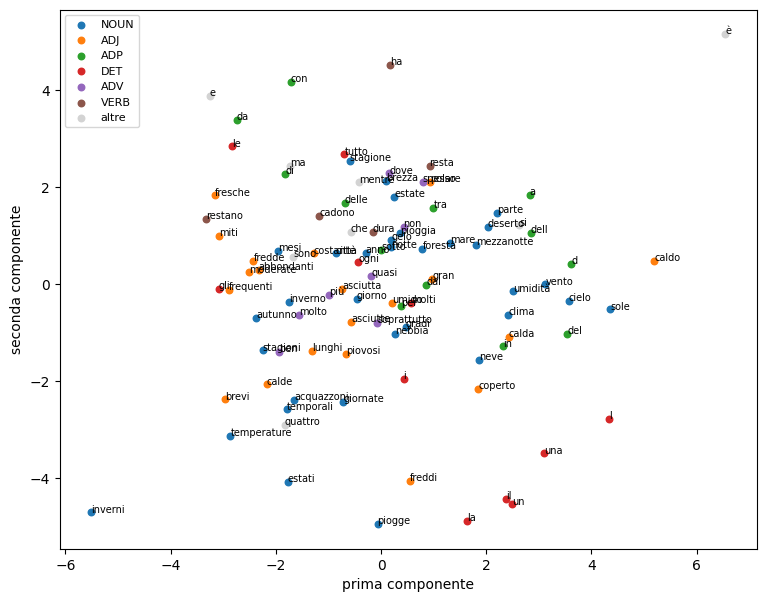

In [8]:
comuni = np.flatnonzero(frequenza >= 6)
E = vettori_contesto[comuni] - vettori_contesto[comuni].mean(axis=0)
_, _, Vt = np.linalg.svd(E, full_matrices=False)
piano = E @ Vt[:2].T

cat_comuni = categorie[comuni]
principali = [c for c in pd.Series(cat_comuni).value_counts().index[:6]]
colori = dict(zip(principali, plt.cm.tab10.colors))

fig, ax = plt.subplots(figsize=(9, 7))
for c in principali:
    m = cat_comuni == c
    ax.scatter(piano[m, 0], piano[m, 1], s=22, color=colori[c], label=c)
altri = ~np.isin(cat_comuni, principali)
ax.scatter(piano[altri, 0], piano[altri, 1], s=22, color='lightgray', label='altre')
for k, j in enumerate(comuni):
    ax.text(piano[k, 0], piano[k, 1], vocabolario[j], fontsize=7)
ax.legend(fontsize=8)
ax.set_xlabel('prima componente')
ax.set_ylabel('seconda componente')
plt.show()

## Un momento di riflessione

- I colori formano gruppi? Quali categorie sono più separate e quali più mescolate?
- Nella proiezione si perde molta informazione: da 16 numeri a 2. Perché una vicinanza nel piano non garantisce una vicinanza nello spazio a 16 dimensioni?
- Nel notebook precedente il piano divideva le parole per clima. Qui divide le parole per... che cosa? Come si spiega?
- Se avessimo molte più frasi, cento volte quelle che abbiamo, che cosa ci aspettiamo che cambi?

## Cosa abbiamo visto

1. Il **contesto** di una parola è l'insieme delle parole vicine. Ogni posizione di ogni testo diventa un esempio di addestramento, **senza etichette** date da una persona.
2. La rete prevede la parola dal suo contesto: l'ingresso è la media dei vettori delle parole di contesto, il livello intermedio ha 16 dimensioni, l'uscita ha una classe per ogni parola.
3. Con il training la rete impara a prevedere anche contesti nuovi: la probabilità si concentra su parole che nel testo compaiono in posti simili (*caldo*, *freddi*).
4. Quello che la rete ha imparato sta nei **vettori delle parole** (le righe di $W_1$). Parole usate negli stessi contesti hanno vettori vicini: *umido* è vicina a *afoso*, *giugno* a *maggio* e *luglio*, *freddi* a *gelidi* e *rigidi*.
5. Rispetto al vettore per classe, il vettore da contesto cattura, almeno in parte, un significato più **generale**: somiglianze grammaticali e di campo semantico che le cinque etichette non potevano contenere.
6. Il risultato è limitato dalla quantità di dati: con meno di tremila parole di testo i vettori sono rumorosi. Con molto più testo è ciò che si chiama **word embedding**.

Restano aperte alcune domande su come procedere:

- **Più testo, più dimensioni.** Vettori utili si ottengono con milioni di frasi e centinaia di dimensioni. Come si scelgono dimensione e finestra?
- **Una parola, un vettore.** *banco* ha sempre lo stesso vettore, di scuola o di pesci. Come si fa a far dipendere il vettore dal contesto della singola frase?
- **L'ordine delle parole.** La media dei vettori non distingue «il cane morde l'uomo» da «l'uomo morde il cane». Che cosa serve per tenerne conto?
- **Usare i vettori per altri compiti.** I vettori appresi su un compito si possono riutilizzare per classificare testi o cercarli? Che cosa si guadagna rispetto a partire da zero?